In [1]:
import os, sys
os.chdir("..")            # notebooks/ se root pe aao
sys.path.insert(0, os.getcwd())
print(os.getcwd())        # D:\neuro hona chahiye

d:\neuro


In [2]:
from src.preprocessing.io import parse_summary, load_edf
from src.preprocessing.windowing import make_windows

RAW_DIR = "data/raw/a/chbmit/chb01"   # rename kiya ho toh data/raw/seizure/chb01
labels = parse_summary(f"{RAW_DIR}/chb01-summary.txt")

n_seiz = sum(len(v) for v in labels.values())
print(len(labels), "files,", n_seiz, "seizures")   # expected: 42 files, 7 seizures
print({k: v for k, v in labels.items() if v})      # sirf seizure wali files

42 files, 7 seizures
{'chb01_03.edf': [(2996, 3036)], 'chb01_04.edf': [(1467, 1494)], 'chb01_15.edf': [(1732, 1772)], 'chb01_16.edf': [(1015, 1066)], 'chb01_18.edf': [(1720, 1810)], 'chb01_21.edf': [(327, 420)], 'chb01_26.edf': [(1862, 1963)]}


In [3]:
raw = load_edf(f"{RAW_DIR}/chb01_03.edf")
print(raw.info["sfreq"], len(raw.ch_names))
print(raw.ch_names)

256.0 23
['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']


In [4]:
from pathlib import Path
from collections import Counter
import mne

layouts = {}
for f in sorted(Path(RAW_DIR).glob("*.edf")):
    r = mne.io.read_raw_edf(f, preload=False, verbose="error")  # sirf header, fast
    layouts[f.name] = tuple(r.ch_names)

common = Counter(layouts.values())
print(len(common), "unique channel layouts")
for layout, n in common.most_common():
    print(n, "files ->", len(layout), "channels")

main = common.most_common(1)[0][0]
print("odd files:", [k for k, v in layouts.items() if v != main])

1 unique channel layouts
42 files -> 23 channels
odd files: []


Sampling rate: 256.0 Hz
Channels: 23
Duration: 60.00 minutes
Using matplotlib as 2D backend.


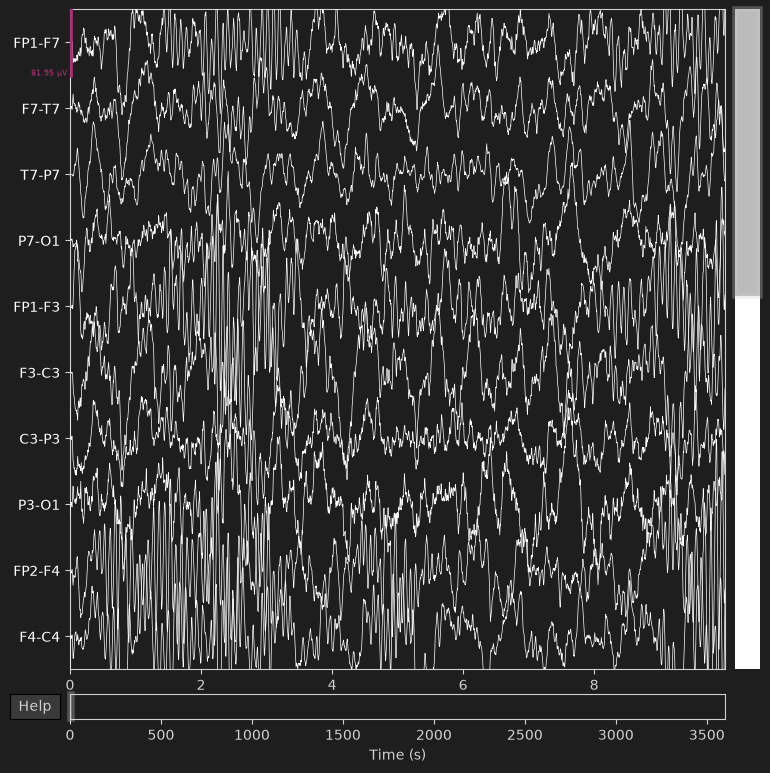

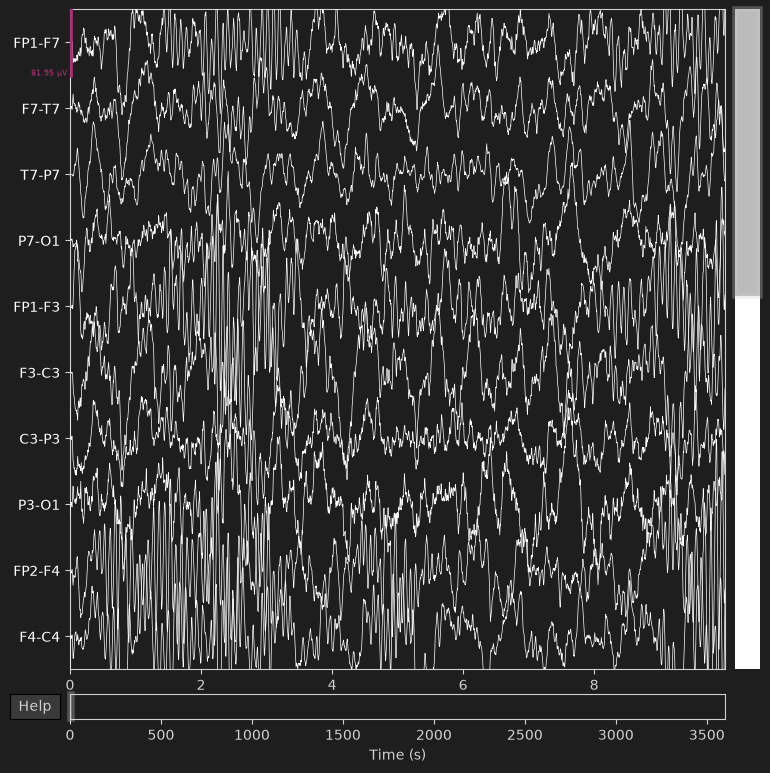

In [5]:
import matplotlib.pyplot as plt

raw = load_edf(f"{RAW_DIR}/chb01_03.edf")

print(f"Sampling rate: {raw.info['sfreq']} Hz")
print(f"Channels: {len(raw.ch_names)}")
print(f"Duration: {raw.times[-1] / 60:.2f} minutes")

raw.plot(
    duration=10,
    n_channels=10,
    scalings="auto",
    title="NeuroScope: Raw EEG"
)

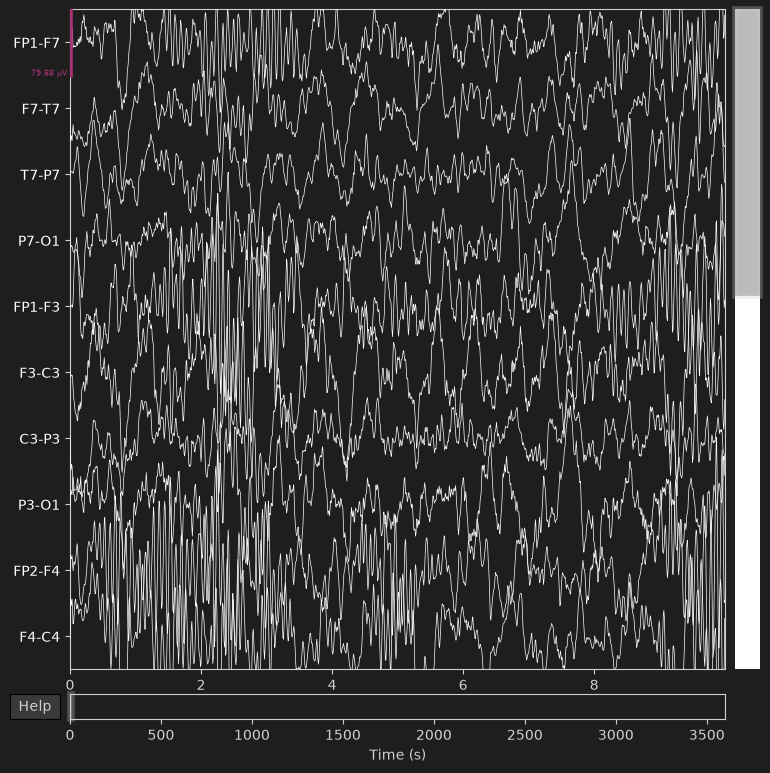

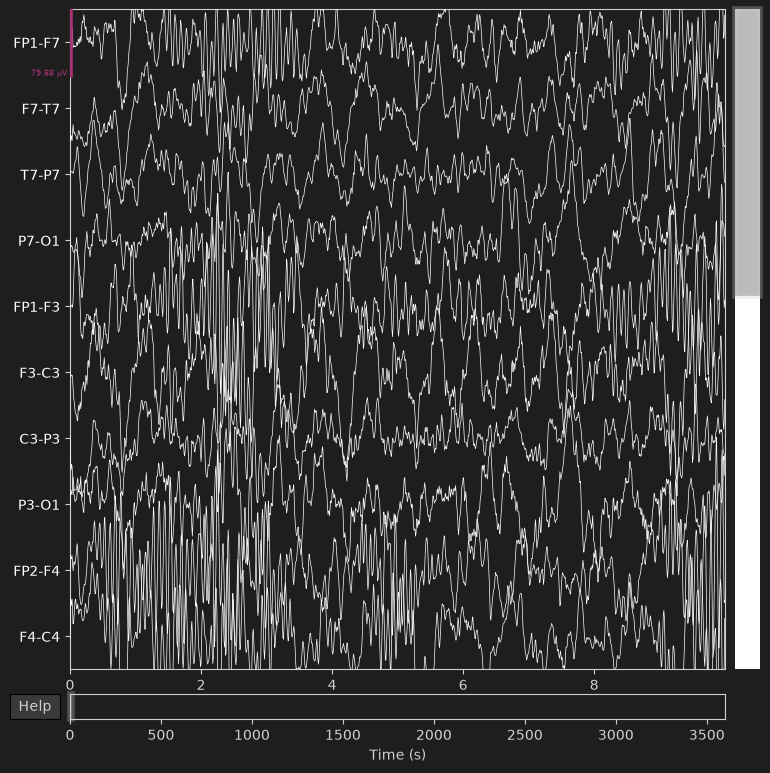

In [6]:
filtered = raw.copy()
filtered.filter(
    l_freq=0.5,
    h_freq=40.0,
    verbose=False
)

filtered.plot(
    duration=10,
    n_channels=10,
    scalings="auto",
    title="NeuroScope: Filtered EEG"
)

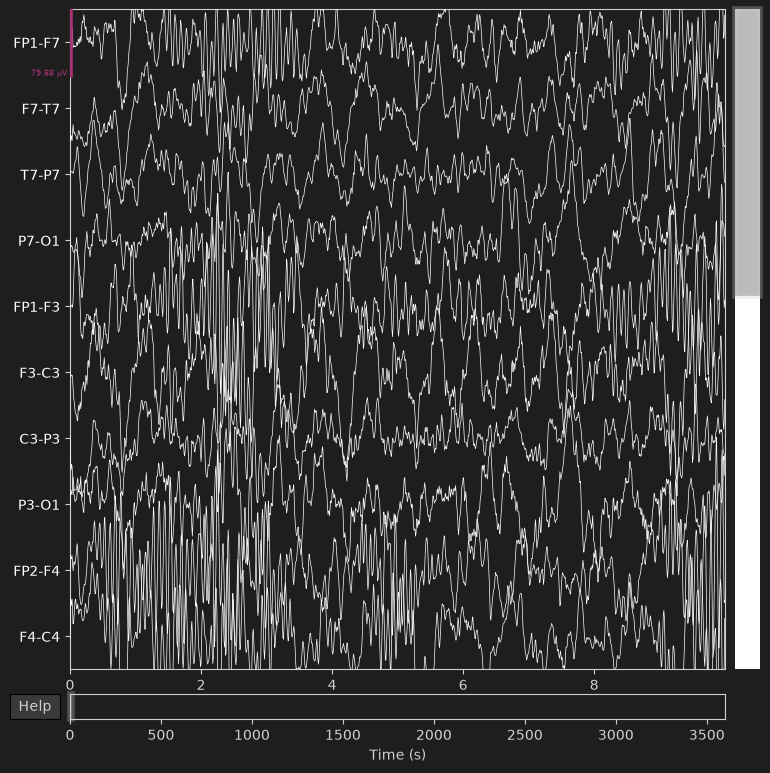

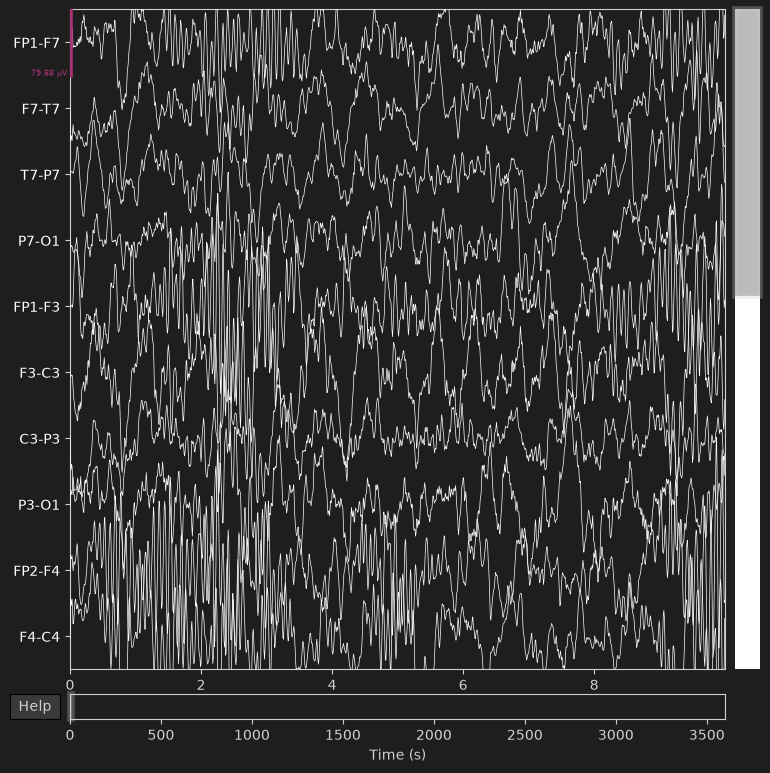

In [7]:
filtered.plot(
    duration=10,
    n_channels=10,
    scalings="auto",
    title="Filtered EEG"
)

In [8]:
import numpy as np

original = raw.get_data()
processed = filtered.get_data()

difference = processed - original

print("Original standard deviation:", np.std(original))
print("Filtered standard deviation:", np.std(processed))
print("Mean absolute change:", np.mean(np.abs(difference)))
print("Maximum absolute change:", np.max(np.abs(difference)))

Original standard deviation: 4.259739245922266e-05
Filtered standard deviation: 4.177958608479413e-05
Mean absolute change: 3.8002723211444794e-06
Maximum absolute change: 0.00024290280485598942


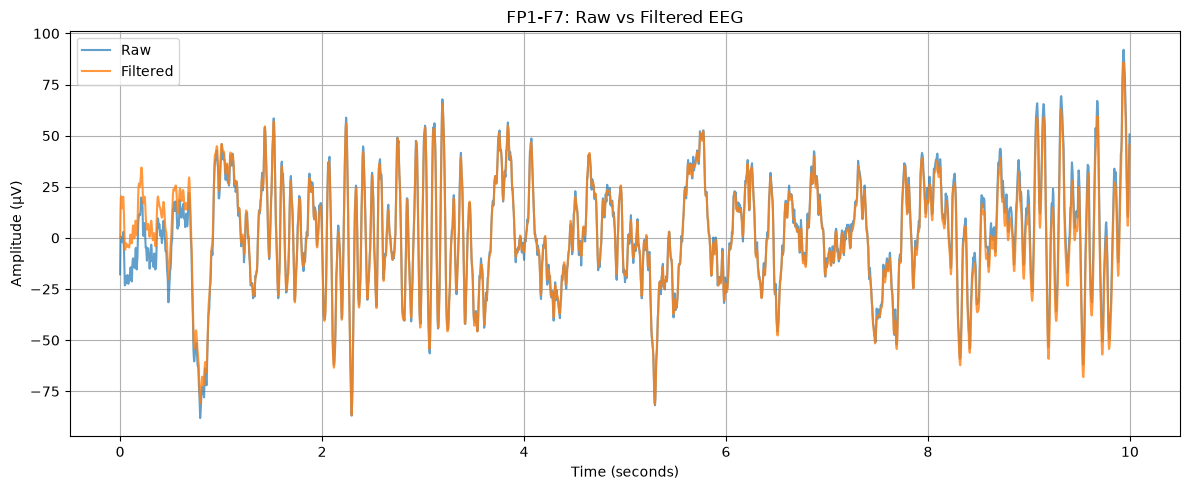

In [9]:
import matplotlib.pyplot as plt

channel = "FP1-F7"
start = 0
duration = 10

original_channel = raw.get_data(
    picks=[channel],
    start=int(start * raw.info["sfreq"]),
    stop=int((start + duration) * raw.info["sfreq"])
)[0] * 1e6

filtered_channel = filtered.get_data(
    picks=[channel],
    start=int(start * filtered.info["sfreq"]),
    stop=int((start + duration) * filtered.info["sfreq"])
)[0] * 1e6

times = np.arange(len(original_channel)) / raw.info["sfreq"]

plt.figure(figsize=(12, 5))
plt.plot(times, original_channel, label="Raw", alpha=0.7)
plt.plot(times, filtered_channel, label="Filtered", alpha=0.8)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title(f"{channel}: Raw vs Filtered EEG")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
"""We loaded the CHB-MIT EEG recording using MNE-Python and inspected its sampling rate, channels, and raw signal waveforms.

We applied a 0.5–40 Hz band-pass filter to attenuate frequencies outside the selected range and compared the raw and filtered signals to examine the effect of preprocessing."""

'We loaded the CHB-MIT EEG recording using MNE-Python and inspected its sampling rate, channels, and raw signal waveforms.\n\nWe applied a 0.5–40 Hz band-pass filter to attenuate frequencies outside the selected range and compared the raw and filtered signals to examine the effect of preprocessing.'

In [11]:
"""Further, we are gonna this recording of 256 Hz sampling into 10-second windows. Then we will have 256x10= 2560 samples per channel. With 23 channels, each window will contains 23x2560= 58880 signal values."""

'Further, we are gonna this recording of 256 Hz sampling into 10-second windows. Then we will have 256x10= 2560 samples per channel. With 23 channels, each window will contains 23x2560= 58880 signal values.'

In [12]:
import numpy as np

# Configuration
WINDOW_SECONDS = 10
SFREQ = filtered.info["sfreq"]

# Convert seconds into samples
WINDOW_SAMPLES = int(WINDOW_SECONDS * SFREQ)

# Get EEG data: channels × samples
eeg_data = filtered.get_data()

# Calculate how many complete windows fit
n_channels, n_samples = eeg_data.shape
n_windows = n_samples // WINDOW_SAMPLES

# Discard any incomplete remainder at the end
usable_samples = n_windows * WINDOW_SAMPLES
eeg_data = eeg_data[:, :usable_samples]

# Divide into windows
windows = eeg_data.reshape(
    n_channels,
    n_windows,
    WINDOW_SAMPLES
).transpose(1, 0, 2)

print("Sampling rate:", SFREQ, "Hz")
print("Channels:", n_channels)
print("Window duration:", WINDOW_SECONDS, "seconds")
print("Samples per window per channel:", WINDOW_SAMPLES)
print("Number of windows:", len(windows))
print("Window array shape:", windows.shape)

Sampling rate: 256.0 Hz
Channels: 23
Window duration: 10 seconds
Samples per window per channel: 2560
Number of windows: 360
Window array shape: (360, 23, 2560)


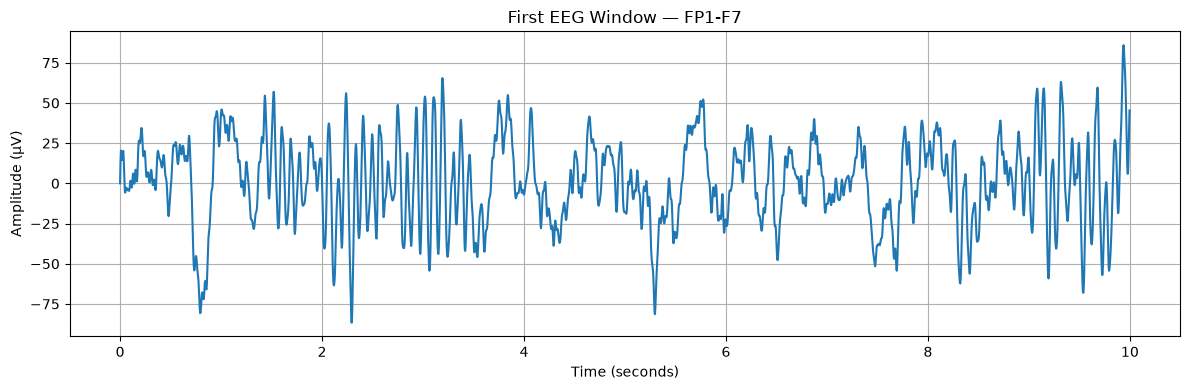

In [13]:
import matplotlib.pyplot as plt

times = np.arange(WINDOW_SAMPLES) / SFREQ

plt.figure(figsize=(12, 4))
plt.plot(times, windows[0, 0, :] * 1e6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title(
    f"First EEG Window — {filtered.ch_names[0]}"
)
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# Inspect the recording's timing
print("Recording:", raw.filenames)
print("Sampling rate:", raw.info["sfreq"], "Hz")
print("Duration:", raw.times[-1], "seconds")

# Inspect the annotation dictionary
print(labels.get("chb01_03.edf"))

Recording: (WindowsPath('d:/neuro/data/raw/a/chbmit/chb01/chb01_03.edf'),)
Sampling rate: 256.0 Hz
Duration: 3599.99609375 seconds
[(2996, 3036)]


In [15]:
# Seizure intervals for this recording, in seconds
seizure_intervals = labels.get("chb01_03.edf", [])

# Create one label for each 10-second window
window_labels = []

for i in range(n_windows):
    window_start = i * WINDOW_SECONDS
    window_end = window_start + WINDOW_SECONDS

    # Check whether this window overlaps a seizure
    is_seizure = any(
        window_start < seizure_end and window_end > seizure_start
        for seizure_start, seizure_end in seizure_intervals
    )

    window_labels.append(int(is_seizure))

# Convert labels to a NumPy array
window_labels = np.array(window_labels)

print("Total windows:", len(window_labels))
print("Non-seizure windows:", np.sum(window_labels == 0))
print("Seizure windows:", np.sum(window_labels == 1))

Total windows: 360
Non-seizure windows: 355
Seizure windows: 5


In [16]:
# Display windows near the known seizure
for i, label in enumerate(window_labels):
    start = i * WINDOW_SECONDS
    end = start + WINDOW_SECONDS

    if 2980 <= start <= 3050:
        print(f"Window {i}: {start}-{end} seconds | Label: {label}")

Window 298: 2980-2990 seconds | Label: 0
Window 299: 2990-3000 seconds | Label: 1
Window 300: 3000-3010 seconds | Label: 1
Window 301: 3010-3020 seconds | Label: 1
Window 302: 3020-3030 seconds | Label: 1
Window 303: 3030-3040 seconds | Label: 1
Window 304: 3040-3050 seconds | Label: 0
Window 305: 3050-3060 seconds | Label: 0


In [17]:
import numpy as np
import pandas as pd

# Extract statistical features from every EEG window
feature_rows = []

for window in windows:
    features = {}

    for ch_idx, ch_name in enumerate(filtered.ch_names):
        signal = window[ch_idx]

        features[f"{ch_name}_mean"] = np.mean(signal)
        features[f"{ch_name}_std"] = np.std(signal)
        features[f"{ch_name}_min"] = np.min(signal)
        features[f"{ch_name}_max"] = np.max(signal)

    feature_rows.append(features)

# Convert extracted features into a DataFrame
X = pd.DataFrame(feature_rows)

# Store the corresponding seizure labels
y = pd.Series(window_labels, name="seizure")

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("\nFirst five rows:")
display(X.head())

Feature matrix shape: (360, 92)
Label vector shape: (360,)

First five rows:


,FP1-F7_mean,FP1-F7_std,FP1-F7_min,FP1-F7_max,F7-T7_mean,F7-T7_std,F7-T7_min,F7-T7_max,T7-P7_mean,T7-P7_std,...,FT9-FT10_min,FT9-FT10_max,FT10-T8_mean,FT10-T8_std,FT10-T8_min,FT10-T8_max,T8-P8-1_mean,T8-P8-1_std,T8-P8-1_min,T8-P8-1_max
0,9.434904e-07,0.000027,-0.000087,0.000086,-2.225630e-06,0.000028,-0.000101,0.000076,4.565986e-07,0.000028,...,-0.000085,0.000097,2.844761e-06,0.000019,-0.000053,0.000072,3.327930e-06,0.000029,-0.000078,0.000097
1,-1.340178e-08,0.000030,-0.000135,0.000098,-5.352066e-07,0.000027,-0.000092,0.000076,-8.623152e-07,0.000033,...,-0.000099,0.000106,-2.717038e-07,0.000015,-0.000055,0.000044,-1.711838e-07,0.000029,-0.000093,0.000097
2,4.626593e-08,0.000036,-0.000129,0.000129,1.564825e-06,0.000035,-0.000124,0.000109,2.789105e-06,0.000038,...,-0.000138,0.000178,1.522929e-06,0.000023,-0.000066,0.000110,1.602737e-06,0.000032,-0.000091,0.000143
3,-2.906662e-07,0.000067,-0.000239,0.000202,-4.564066e-07,0.000040,-0.000210,0.000133,-1.122093e-06,0.000048,...,-0.000149,0.000189,-8.481326e-07,0.000034,-0.000120,0.000130,3.132189e-07,0.000050,-0.000155,0.000165
4,-2.467865e-07,0.000026,-0.000121,0.000095,-4.788114e-07,0.000023,-0.000089,0.000081,-1.009455e-06,0.000024,...,-0.000132,0.000131,-5.734434e-07,0.000015,-0.000069,0.000043,-1.728021e-06,0.000034,-0.000143,0.000126


In [18]:
"""After the division of the EEG recording into 10-second windows, we extracted statistical features for each channel in every window. The resulting feature matrix `X` contains mean, standard deviation, minimum, and maximum values for each channel, while the label vector `y` indicates whether each window corresponds to a seizure or not. This structured representation of the EEG data is now ready for further analysis or machine learning tasks."""

'After the division of the EEG recording into 10-second windows, we extracted statistical features for each channel in every window. The resulting feature matrix `X` contains mean, standard deviation, minimum, and maximum values for each channel, while the label vector `y` indicates whether each window corresponds to a seizure or not. This structured representation of the EEG data is now ready for further analysis or machine learning tasks.'

In [19]:
# Check data quality
print("Missing values:", X.isna().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

# Check class distribution
print("\nLabel distribution:")
print(y.value_counts().sort_index())

# Check class percentages
print("\nLabel percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Missing values: 0
Infinite values: 0

Label distribution:
seizure
0    355
1      5
Name: count, dtype: int64

Label percentages:
seizure
0    98.61
1     1.39
Name: proportion, dtype: float64


In [20]:
# Display every recording that has seizure annotations
print("Recordings with seizure annotations:\n")

for filename, intervals in labels.items():
    if intervals:
        print(f"{filename}: {intervals}")

Recordings with seizure annotations:

chb01_03.edf: [(2996, 3036)]
chb01_04.edf: [(1467, 1494)]
chb01_15.edf: [(1732, 1772)]
chb01_16.edf: [(1015, 1066)]
chb01_18.edf: [(1720, 1810)]
chb01_21.edf: [(327, 420)]
chb01_26.edf: [(1862, 1963)]
